# 02 — Primeiro Modelo: Regressão Linear

No notebook 01 nós **olhamos** os dados. Agora vamos treinar o primeiro modelo de Machine Learning para **prever** o valor das casas.

**O que você vai aprender aqui:**
1. O que é aprendizado supervisionado e regressão
2. Separar atributos (`X`) e alvo (`y`)
3. Dividir os dados em treino e teste, e por que isso é essencial
4. Criar um modelo de referência (baseline)
5. Medir o erro de um modelo: MAE, RMSE e R²
6. Treinar uma regressão linear com uma variável e depois com todas
7. Diagnosticar onde o modelo erra

> Lembrete: execute as células em ordem com `Shift + Enter`.

## 🎓 Conceito: aprendizado supervisionado

Em Machine Learning **supervisionado**, nós mostramos ao computador muitos exemplos em que **já sabemos a resposta**. O algoritmo procura padrões que liguem as informações de entrada à resposta.

- **Atributos** (*features*), chamados de `X`: as informações de entrada. Aqui: renda, idade das casas, localização...
- **Alvo** (*target*), chamado de `y`: o que queremos prever. Aqui: `MedHouseVal`, o valor da casa.

Depois de **treinado**, o modelo consegue prever `y` para dados que ele nunca viu.

Quando o alvo é um **número contínuo** (como um preço), o problema se chama **regressão**. Quando o alvo é uma **categoria** (ex.: "spam" ou "não spam"), chama-se **classificação**. Este projeto é de regressão.

## 1. Importando bibliotecas e carregando os dados

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing

# Ferramentas novas deste notebook (cada uma será explicada quando for usada):
from sklearn.model_selection import train_test_split   # divide os dados em treino e teste
from sklearn.dummy import DummyRegressor               # modelo "bobo", usado como referência
from sklearn.linear_model import LinearRegression      # o modelo de regressão linear
from sklearn.metrics import (                          # funções que medem o erro
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

pd.set_option("display.precision", 3)
plt.rcParams["figure.dpi"] = 100

# Mesmo carregamento do notebook 01.
df = fetch_california_housing(as_frame=True).frame
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.325,41.0,6.984,1.024,322.0,2.556,37.88,-122.23,4.526
1,8.301,21.0,6.238,0.972,2401.0,2.110,37.86,-122.22,3.585
2,7.257,52.0,8.288,1.073,496.0,2.802,37.85,-122.24,3.521
3,5.643,52.0,5.817,1.073,558.0,2.548,37.85,-122.25,3.413
4,3.846,52.0,6.282,1.081,565.0,2.181,37.85,-122.25,3.422


## 2. Separando atributos (X) e alvo (y)

In [2]:
# .drop(columns=...) devolve uma cópia da tabela SEM a coluna indicada.
# Assim X fica só com as 8 colunas de entrada.
X = df.drop(columns="MedHouseVal")

# y é apenas a coluna que queremos prever.
y = df["MedHouseVal"]

# Convenção: X maiúsculo (uma tabela, várias colunas), y minúsculo (uma única coluna).
print("X:", X.shape, "-> linhas e colunas de atributos")
print("y:", y.shape, "-> uma coluna só, por isso aparece apenas o número de linhas")

X: (20640, 8) -> linhas e colunas de atributos
y: (20640,) -> uma coluna só, por isso aparece apenas o número de linhas


**Conclusão:** temos 20.640 exemplos. Cada um tem 8 atributos de entrada (`X`) e 1 resposta conhecida (`y`).

## 🎓 Conceito: treino e teste

Imagine um aluno que decora as respostas da lista de exercícios. Ele tira 10 na lista, mas isso não prova que aprendeu: só prova que decorou. Para saber se ele aprendeu de verdade, a prova precisa ter **questões novas**.

Com modelos é igual. Por isso dividimos os dados em duas partes:

- **Treino** (aqui, 80%): o modelo aprende com estes dados.
- **Teste** (aqui, 20%): ficam **guardados**. O modelo nunca os vê durante o treino. Usamos só no fim, para medir se ele **generaliza**, isto é, se acerta em dados novos.

⚠️ **Regra de ouro:** o conjunto de teste não pode influenciar nenhuma decisão do treino. Se influenciar, a nota final fica otimista demais e não reflete o mundo real.

In [3]:
# train_test_split embaralha as linhas e as divide em duas partes.
#   test_size=0.2    -> 20% das linhas vão para o teste
#   random_state=42  -> "semente" do embaralhamento. Com o mesmo número,
#                       a divisão sai sempre igual, e os resultados podem ser reproduzidos.
#                       (42 é só uma convenção; qualquer número inteiro serve.)
#
# A função devolve 4 coisas, e o Python permite recebê-las de uma vez,
# separadas por vírgula (isso se chama "desempacotamento"):
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Treino: {len(X_train)} linhas")
print(f"Teste:  {len(X_test)} linhas")

# Conferindo se as duas partes são parecidas: a média do alvo deve ser próxima.
print(f"Média de y no treino: {y_train.mean():.3f}")
print(f"Média de y no teste:  {y_test.mean():.3f}")

Treino: 16512 linhas
Teste:  4128 linhas
Média de y no treino: 2.072
Média de y no teste:  2.055


**Conclusão:** 16.512 linhas para treinar e 4.128 para testar. As médias do alvo são quase iguais (2,07 e 2,06), então o embaralhamento gerou duas partes representativas dos mesmos dados.

## 🎓 Conceito: métricas de erro

Para comparar modelos precisamos de **números** que digam quanto eles erram. Para cada casa, o **erro** é `valor real − valor previsto`. As três métricas mais comuns em regressão são:

| Métrica | Como calcula | Como interpretar |
|---|---|---|
| **MAE** (*Mean Absolute Error*) | Média do tamanho dos erros (sem sinal) | "Em média, erro X para mais ou para menos." Fácil de explicar. |
| **RMSE** (*Root Mean Squared Error*) | Eleva os erros ao quadrado, tira a média e depois a raiz | Mesma unidade do alvo, mas **pune mais os erros grandes**. Sempre ≥ MAE. |
| **R²** (coeficiente de determinação) | Compara o modelo com "chutar sempre a média" | 1.0 = perfeito; 0.0 = tão bom quanto chutar a média; negativo = pior que isso. |

Para MAE e RMSE, **menor é melhor**. Para R², **maior é melhor**.

Lembre que o alvo está em centenas de milhares de dólares: um MAE de 0,5 significa erro médio de **US\$ 50.000**.

Vamos criar uma **função** que calcula as três métricas de uma vez, para não repetir código.

In [4]:
# "def" cria uma função: um bloco de código com nome, que podemos reutilizar.
# Entre parênteses ficam os "parâmetros", que são as entradas da função.
def avaliar(y_real, y_previsto):
    """Calcula MAE, RMSE e R² e devolve tudo num dicionário."""
    # Esse texto entre três aspas é a "docstring": a documentação da função.

    mae = mean_absolute_error(y_real, y_previsto)
    rmse = np.sqrt(mean_squared_error(y_real, y_previsto))   # np.sqrt = raiz quadrada
    r2 = r2_score(y_real, y_previsto)

    # Um dicionário guarda pares "chave: valor", escrito entre chaves {}.
    # "return" devolve o resultado para quem chamou a função.
    # round(valor, 3) arredonda para 3 casas decimais, e float() garante um número
    # decimal comum do Python (sem isso, a saída mostraria "np.float64(...)").
    return {"MAE": round(float(mae), 3), "RMSE": round(float(rmse), 3), "R²": round(float(r2), 3)}


# Exemplo para entender as métricas: 3 casas inventadas.
reais = [2.0, 3.0, 4.0]
previstos = [2.5, 3.0, 3.0]   # erros: -0.5, 0.0, +1.0
avaliar(reais, previstos)

{'MAE': 0.5, 'RMSE': 0.645, 'R²': 0.375}

**Conclusão do exemplo:** os erros são 0,5, 0 e 1,0.
- O **MAE** é a média deles: (0,5 + 0 + 1,0) / 3 = 0,5.
- O **RMSE** fica maior (≈ 0,65), porque o erro de 1,0 pesa mais ao ser elevado ao quadrado.
- O **R²** de 0,375 indica que essas previsões são melhores que chutar a média, mas ainda longe de perfeitas.

## 🎓 Conceito: baseline (modelo de referência)

Antes de comemorar qualquer resultado, precisamos de um **ponto de comparação**. A pergunta é: "meu modelo é melhor do que a estratégia mais simples possível?"

O `DummyRegressor` é um modelo propositalmente bobo: ele **sempre prevê a média** do treino, para qualquer casa. Se um modelo de verdade não superar isso, ele não aprendeu nada útil.

Todo modelo do scikit-learn segue o mesmo padrão de uso:
1. **Criar** o modelo: `modelo = AlgumModelo()`
2. **Treinar** com `modelo.fit(X_train, y_train)`. O modelo aprende com os dados de treino.
3. **Prever** com `modelo.predict(X_novos)`. O modelo responde para dados novos.

In [5]:
# 1. Criar o modelo. Por padrão, o DummyRegressor usa a média.
baseline = DummyRegressor()

# 2. Treinar. Aqui "aprender" é só calcular a média de y_train.
baseline.fit(X_train, y_train)

# 3. Prever para as casas do teste.
previsoes_baseline = baseline.predict(X_test)

# Todas as previsões são iguais: a média do treino.
print("Primeiras 5 previsões:", previsoes_baseline[:5])

avaliar(y_test, previsoes_baseline)

Primeiras 5 previsões: [2.07194694 2.07194694 2.07194694 2.07194694 2.07194694]


{'MAE': 0.906, 'RMSE': 1.145, 'R²': -0.0}

**Conclusão:** chutando sempre ≈ 2,07 (US\$ 207 mil), o erro médio (MAE) é de cerca de **US\$ 90.600** e o R² é praticamente 0, como esperado: este é exatamente o "chute da média" que o R² usa como comparação. (Pode aparecer -0.0: um número negativo minúsculo arredondado. Acontece porque a média do teste é um pouquinho diferente da média do treino.)

Esse é o número a ser batido. Qualquer modelo útil precisa ter um MAE bem menor que 0,906.

## 🎓 Conceito: regressão linear

A regressão linear é um dos modelos mais simples e mais usados. Com **uma** variável, ela procura a **reta** que melhor passa pelos pontos:

$$\text{valor previsto} = a \cdot \text{renda} + b$$

- **`a`** é o **coeficiente** (inclinação): quanto o valor previsto muda quando a renda aumenta 1 unidade.
- **`b`** é o **intercepto**: o valor previsto quando a renda é zero.

"Treinar" significa encontrar os valores de `a` e `b` que deixam a reta o mais perto possível de todos os pontos de treino. Tecnicamente, ela minimiza a soma dos erros ao quadrado (método dos **mínimos quadrados**).

Vamos começar só com `MedInc`, a variável mais correlacionada com o preço no notebook 01.

## 3. Regressão linear com uma variável (renda)

In [6]:
# Colchetes duplos [["MedInc"]] mantêm o resultado como TABELA (DataFrame) de uma coluna.
# O scikit-learn sempre espera X como tabela (2 dimensões), mesmo com uma só coluna.
X_train_renda = X_train[["MedInc"]]
X_test_renda = X_test[["MedInc"]]

modelo_renda = LinearRegression()
modelo_renda.fit(X_train_renda, y_train)

# Depois do .fit(), o modelo guarda o que aprendeu em atributos terminados com "_".
a = modelo_renda.coef_[0]      # coef_ é uma lista (um coeficiente por coluna); pegamos o 1º
b = modelo_renda.intercept_
print(f"Reta aprendida: valor = {a:.3f} × renda + {b:.3f}")

Reta aprendida: valor = 0.419 × renda + 0.445


**Conclusão:** o coeficiente ≈ 0,42 diz que, para cada **+1 na renda** (US\$ 10 mil a mais de renda mediana), o modelo prevê **+0,42 no valor** (cerca de US\$ 42 mil a mais na casa).

Faz sentido: regiões mais ricas têm casas mais caras.

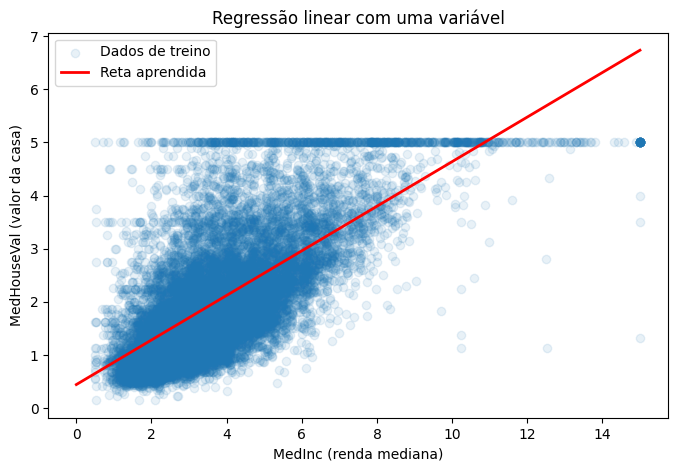

In [7]:
# Vamos desenhar a reta sobre os pontos de treino.
# np.linspace(início, fim, n) gera n números igualmente espaçados: o "eixo" da reta.
renda_grid = pd.DataFrame({"MedInc": np.linspace(0, 15, 100)})
valor_grid = modelo_renda.predict(renda_grid)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(X_train["MedInc"], y_train, alpha=0.1, label="Dados de treino")
ax.plot(renda_grid["MedInc"], valor_grid, color="red", linewidth=2, label="Reta aprendida")
ax.set_xlabel("MedInc (renda mediana)")
ax.set_ylabel("MedHouseVal (valor da casa)")
ax.set_title("Regressão linear com uma variável")
ax.legend()   # mostra a legenda com os "label" definidos acima
plt.show()

**Conclusão:** a reta acompanha a tendência geral (mais renda, casa mais cara), mas os pontos estão bem espalhados em volta dela. A renda sozinha explica só parte do preço.

Repare também que a reta passa de 5,0 para rendas altas, enquanto os dados reais param no teto de 5,0. Uma reta não sabe que existe esse limite.

In [8]:
# Agora a avaliação: prevemos para o TESTE, que o modelo nunca viu.
previsoes_renda = modelo_renda.predict(X_test_renda)
avaliar(y_test, previsoes_renda)

{'MAE': 0.63, 'RMSE': 0.842, 'R²': 0.459}

**Conclusão:** com apenas uma variável, o MAE caiu de 0,906 (baseline) para **0,630**, ou seja, de US\$ 90 mil para US\$ 63 mil de erro médio. O R² de 0,46 indica que a renda sozinha explica cerca de **46% da variação** dos preços.

Já é um ganho real, mas ainda erramos muito.

## 4. Regressão linear com todas as variáveis

Com várias variáveis, a ideia é a mesma, mas agora existe **um coeficiente para cada coluna**:

$$\text{valor} = a_1 \cdot \text{MedInc} + a_2 \cdot \text{HouseAge} + \dots + a_8 \cdot \text{Longitude} + b$$

Em vez de uma reta, o modelo encontra um "plano" em 8 dimensões. Não dá para desenhar, mas o princípio é o mesmo.

In [9]:
modelo_completo = LinearRegression()
modelo_completo.fit(X_train, y_train)   # agora com as 8 colunas

previsoes_completo = modelo_completo.predict(X_test)
avaliar(y_test, previsoes_completo)

{'MAE': 0.533, 'RMSE': 0.746, 'R²': 0.576}

**Conclusão:** usando todas as colunas, o MAE caiu para **0,533** (≈ US\$ 53 mil) e o R² subiu para **0,58**. As outras variáveis, principalmente a localização, trazem informação que a renda sozinha não tinha.

In [10]:
# Um coeficiente por coluna. pd.Series cria uma "coluna" com nomes, mais fácil de ler.
coeficientes = pd.Series(modelo_completo.coef_, index=X_train.columns)
coeficientes.sort_values().round(4)   # .round(4) evita a notação científica (ex.: 2e-06)

Longitude    -0.434
Latitude     -0.420
AveRooms     -0.123
AveOccup     -0.004
Population   -0.000
HouseAge      0.010
MedInc        0.449
AveBedrms     0.783
dtype: float64

**Conclusão (com cuidado!):** é tentador ler os coeficientes como "importância" de cada variável, mas há duas armadilhas:

1. **Escalas diferentes.** `Population` vai até ~35 mil, enquanto `MedInc` vai até ~15. Um coeficiente pequeno numa coluna de valores enormes pode ter um efeito grande. Por isso não dá para comparar os tamanhos diretamente. (No notebook 03 vamos padronizar as escalas e isso fica comparável.)
2. **Colunas parecidas "brigam" entre si.** `AveRooms` e `AveBedrms` são muito correlacionadas (vimos no 01). O modelo deu um coeficiente negativo para cômodos e positivo para quartos, e cada um compensa o outro. Isso se chama **multicolinearidade**.

O que dá para concluir com segurança: os sinais negativos de `Latitude` e `Longitude` indicam que, mantido o resto, as casas ficam mais baratas ao ir para o **norte** (latitude maior) e para o **leste**, longe da costa (longitude maior, ou seja, menos negativa). Isso combina com o mapa do notebook 01.

## 🎓 Conceito: underfitting e overfitting

Comparar o erro no **treino** com o erro no **teste** revela como o modelo está aprendendo:

| Situação | Erro no treino | Erro no teste | Significa |
|---|---|---|---|
| **Underfitting** (subajuste) | alto | alto | Modelo simples demais, não captou os padrões |
| **Bom ajuste** | baixo | baixo, parecido com o treino | Aprendeu e generaliza |
| **Overfitting** (sobreajuste) | muito baixo | bem mais alto | "Decorou" o treino, como o aluno da lista |

## 5. Comparando os modelos

In [11]:
# Um dicionário com os 3 modelos e as colunas que cada um usa.
modelos = {
    "Baseline (média)": (baseline, X.columns),
    "Linear (só renda)": (modelo_renda, ["MedInc"]),
    "Linear (todas)": (modelo_completo, X.columns),
}

resultados = []   # lista vazia que vamos preencher
for nome, (modelo, colunas) in modelos.items():   # .items() percorre pares chave/valor
    treino = avaliar(y_train, modelo.predict(X_train[colunas]))
    teste = avaliar(y_test, modelo.predict(X_test[colunas]))
    # .append() adiciona um item ao final da lista
    resultados.append({
        "Modelo": nome,
        "MAE treino": treino["MAE"], "MAE teste": teste["MAE"],
        "RMSE teste": teste["RMSE"],
        "R² treino": treino["R²"], "R² teste": teste["R²"],
    })

# Transformamos a lista de dicionários numa tabela; set_index usa o nome como rótulo das linhas.
tabela = pd.DataFrame(resultados).set_index("Modelo")
tabela.round(3)

,MAE treino,MAE teste,RMSE teste,R² treino,R² teste
Modelo,,,,,
Baseline (média),0.914,0.906,1.145,0.000,-0.000
Linear (só renda),0.625,0.630,0.842,0.477,0.459
Linear (todas),0.529,0.533,0.746,0.613,0.576


**Conclusão:**
- Cada passo melhorou o anterior. O MAE no teste foi de 0,906 → 0,630 → 0,533.
- Treino e teste estão **muito próximos** em todos os modelos (ex.: R² de 0,61 no treino e 0,58 no teste). Ou seja, **não há overfitting**.
- Como o R² ainda é ~0,58, o erro é alto nos dois conjuntos. Isso indica **underfitting**: uma reta (ou plano) é simples demais para a relação real entre as variáveis e o preço. Isso motiva os modelos não lineares do notebook 04.

## 6. Diagnóstico: onde o modelo erra?

As métricas resumem o erro num único número. Gráficos mostram **onde** e **como** o modelo erra.

🎓 **Resíduo** é o nome do erro de cada previsão: `resíduo = valor real − valor previsto`.
- Resíduo positivo: o modelo previu **menos** que o real (subestimou).
- Resíduo negativo: o modelo previu **mais** que o real (superestimou).

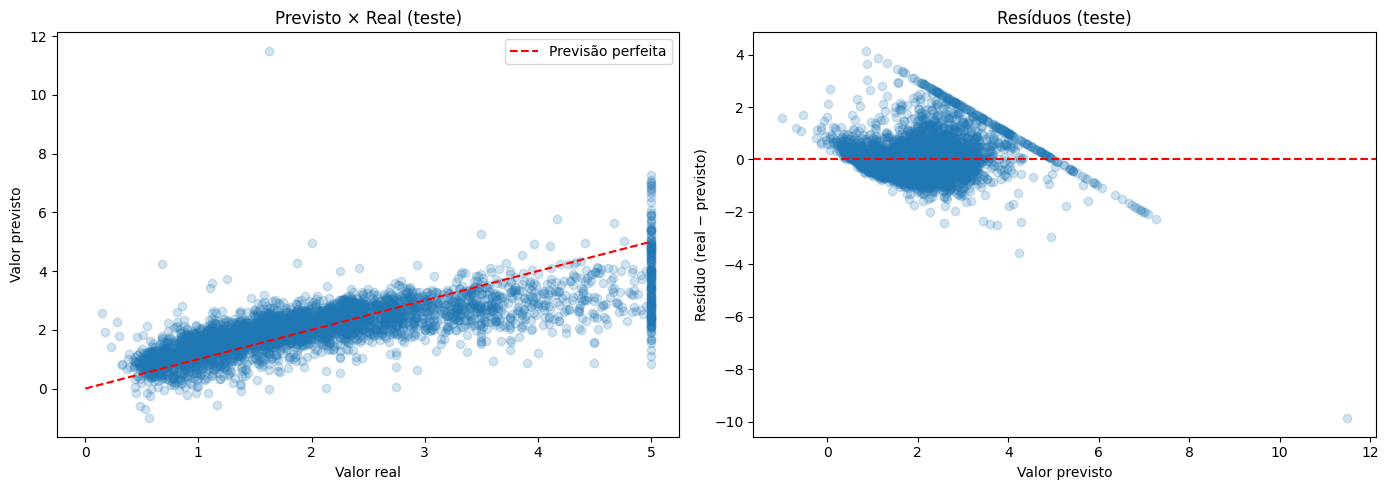

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: previsto × real. Se o modelo fosse perfeito, todos os pontos
# cairiam sobre a linha diagonal vermelha (previsto = real).
axes[0].scatter(y_test, previsoes_completo, alpha=0.2)
axes[0].plot([0, 5], [0, 5], color="red", linestyle="--", label="Previsão perfeita")
axes[0].set_xlabel("Valor real")
axes[0].set_ylabel("Valor previsto")
axes[0].set_title("Previsto × Real (teste)")
axes[0].legend()

# Gráfico 2: resíduos × previsto. Num modelo bom, os pontos ficam espalhados
# aleatoriamente em volta do zero, sem formar padrões.
residuos = y_test - previsoes_completo
axes[1].scatter(previsoes_completo, residuos, alpha=0.2)
axes[1].axhline(0, color="red", linestyle="--")   # linha horizontal no zero
axes[1].set_xlabel("Valor previsto")
axes[1].set_ylabel("Resíduo (real − previsto)")
axes[1].set_title("Resíduos (teste)")

plt.tight_layout()
plt.show()

**Conclusão:**
- **Coluna de pontos em real = 5,0** (gráfico da esquerda): são as casas limitadas no teto. O valor real delas pode ser bem maior que 5,0, mas o dado diz 5,0, e o modelo prevê valores variados.
- **Linha diagonal descendente** (gráfico da direita): é a mesma coluna das casas no teto, vista pelos resíduos.
- **Previsões fora do possível:** algumas previsões ficam negativas (preço negativo!) e outras passam de 5. Uma regressão linear não conhece os limites dos dados.
- **Os resíduos não são aleatórios:** existe padrão. Isso confirma que o modelo linear deixa de captar parte da estrutura dos dados.

Vamos contar esses casos:

In [13]:
# Comparações geram True/False; .sum() conta os True.
print("Previsões negativas:   ", (previsoes_completo < 0).sum())
print("Previsões acima de 5.0:", (previsoes_completo > 5).sum())

# Resíduo médio separando casas no teto e as demais.
# y_test >= 5 é um "filtro": seleciona só as linhas em que a condição é True.
no_teto = y_test >= 5
print(f"Resíduo médio das casas no teto: {residuos[no_teto].mean():+.2f}")
print(f"Resíduo médio das demais:        {residuos[~no_teto].mean():+.2f}")   # ~ inverte o filtro

Previsões negativas:    15
Previsões acima de 5.0: 39
Resíduo médio das casas no teto: +1.15
Resíduo médio das demais:        -0.05


**Conclusão:** 15 previsões negativas e 39 acima de 5,0, de um total de 4.128. Nas casas que estão no teto, o modelo **subestima** em média 1,15 (≈ US\$ 115 mil). Nas demais, o erro médio fica perto de zero.

O teto do alvo é um dos maiores problemas deste dataset. Vamos tratá-lo no notebook 03.

## 7. Usando o modelo para prever uma casa

No fim das contas, o objetivo de um modelo é **prever casos novos**. Vamos pegar uma casa do teste e ver a previsão de cada modelo.

In [14]:
# .iloc[[0]] pega a primeira linha do teste, mantendo o formato de tabela (colchetes duplos).
casa = X_test.iloc[[0]]
casa

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
20046,1.681,25.0,4.192,1.022,1392.0,3.877,36.06,-119.01


In [16]:
valor_real = y_test.iloc[0]
print(f"Valor real:                US$ {valor_real * 100_000:>9,.0f}")

# O "_" em 100_000 é só um separador visual; para o Python é o número 100000.
# :>9,.0f -> alinha à direita em 9 espaços, separa milhares com vírgula e usa 0 casas decimais.
for nome, (modelo, colunas) in modelos.items():
    previsto = modelo.predict(casa[colunas])[0]
    print(f"{nome:<26} US$ {previsto * 100_000:>9,.0f}")

Valor real:                US$    47,700
Baseline (média)           US$   207,195
Linear (só renda)          US$   114,959
Linear (todas)             US$    71,912


**Conclusão:** para esta casa (valor real ≈ US\$ 47.700), todos os modelos erram bastante. Mesmo o melhor prevê ≈ US\$ 72 mil.

Isso mostra que um bom R² médio não garante acerto em cada caso. As métricas falam do **conjunto**, e casos individuais podem errar muito.

## 8. Resumo e próximos passos

**Conceitos que você aprendeu**
- **Aprendizado supervisionado**: aprender a partir de exemplos com resposta conhecida (`X` → `y`).
- **Regressão**: prever um número contínuo.
- **Treino/teste**: avaliar sempre em dados que o modelo nunca viu.
- **Baseline**: o ponto de comparação mínimo.
- **MAE, RMSE, R²**: como medir o erro.
- **Regressão linear**, **coeficientes** e **multicolinearidade**.
- **Underfitting × overfitting**.
- **Resíduos** e o diagnóstico de erros.

**Resultados no teste**

| Modelo | MAE | R² |
|---|---|---|
| Baseline (média) | 0,906 | 0,00 |
| Linear (só renda) | 0,630 | 0,46 |
| Linear (todas) | 0,533 | 0,58 |

**Principais problemas encontrados**
1. **Underfitting**: o modelo linear é simples demais para os dados.
2. **Teto em 5,0**: distorce o alvo e as previsões.
3. **Escalas diferentes**: impedem comparar os coeficientes.
4. **Previsões impossíveis**: valores negativos e acima do teto.

**Próximo notebook (03):** pré-processamento e `Pipeline`. Vamos padronizar escalas, tratar o teto e os outliers e usar os atributos derivados do notebook 01.